In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display, Math

from src.grid import Grid, PolarGrid
from src.elementary_solutions import SourceSink, Doublet, Vortex, UniformFlow
from src.superposition import DoubletFreestream, DoubletVortexFreestream

# Joukowski Transformation

## 1. Complex numbers in Python

In [2]:
3 + 2j

(3+2j)

In [3]:
a = 3
b= 3
z = a + b * 1j
print ('z = ', z)
print('The type of the variable is ', type(z))

z =  (3+3j)
The type of the variable is  <class 'complex'>


In [4]:
# 1.
z1 = (2.75 + 3.69j) * (8.55 - 6.13j)

display(Math(rf'1.\quad (2.75+3.69i)\times(8.55-6.13i) = {z1.real:.2f}{z1.imag:+.2f}i'))


# 2.

z2 = 1.4 * np.exp(1j*5.32)

display(Math(rf'2.\quad 1.4\times e^{{i\,5.32}} = {z2.real:.2f}{z2.imag:+.2f}i'))

# 3.

z3 = (7.51 - 9.15j) / (4.43 + 9.64j)

display(Math(rf'3. \quad \frac{{7.51-9.15i}}{{4.43+9.64i}} = {z3.real:.2f}{z3.imag:+.2f}i'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 2. Shapes created by the Joukowski transformation

In [5]:
def joukowski_transformation(z, c):

    return z + c**2 / z

In [6]:
c = 1

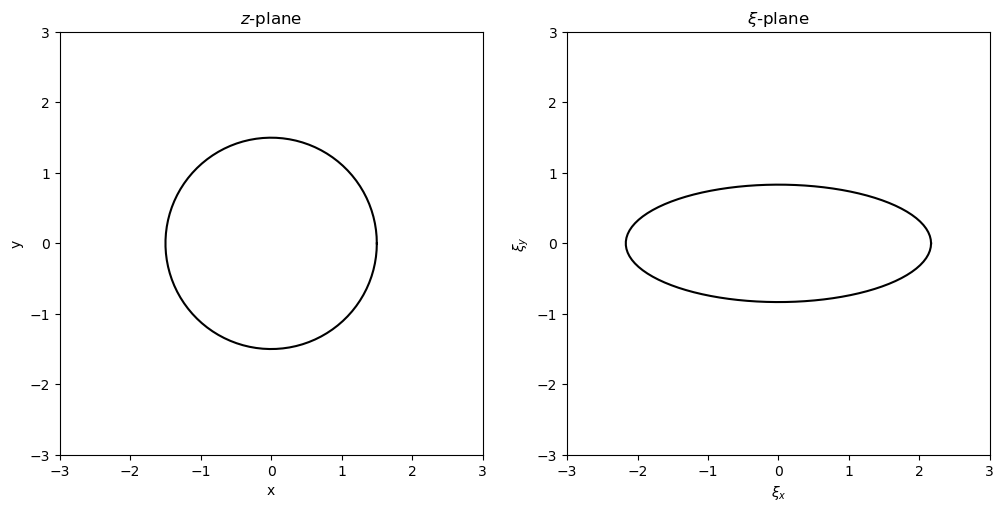

In [7]:

# 1.

R = 1.5
theta = np.linspace(0, 2 * np.pi, 100)
z = R * np.exp(1j * theta)
xi = joukowski_transformation(z, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z.real, z.imag, color='k')
ax[0].set_xlim(-3, 3)
ax[0].set_ylim(-3, 3)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi.real, xi.imag, color='k')
ax[1].set_xlim(-3, 3)
ax[1].set_ylim(-3, 3)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

1. On the $z$-plane, place a circle with radius $R$ larger than $c=1$, say $R=1.5$, centered at the origin. What does the shape look like when mapped on the $\xi$-plane?
    2. ellipse

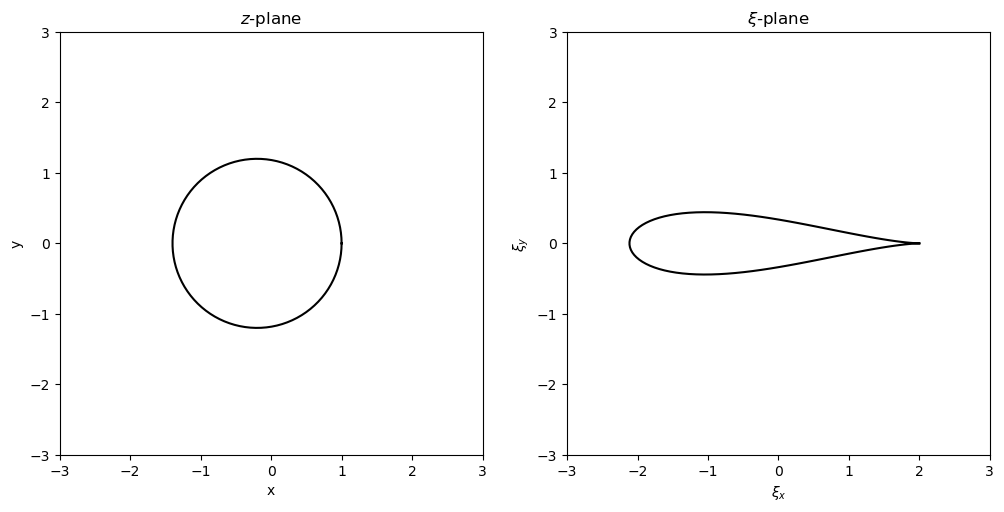

In [8]:
# 2.

R = 1.2
theta = np.linspace(0, 2 * np.pi, 100)
xc = c - R
yc = 0
z =  (xc + yc * 1j) + R * np.exp(1j * theta)
xi = joukowski_transformation(z, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z.real, z.imag, color='k')
ax[0].set_xlim(-3, 3)
ax[0].set_ylim(-3, 3)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi.real, xi.imag, color='k')
ax[1].set_xlim(-3, 3)
ax[1].set_ylim(-3, 3)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

2. Now, place a circle on the $z$-plane with radius such that $c \lt R \lt 2c$ (e.g., $c=1$; $R=1.2$), centered at $(x_c,y_c)=(c-R, 0)$. What does the shape look like on the $\xi$-plane?
    3. symmetric airfoil

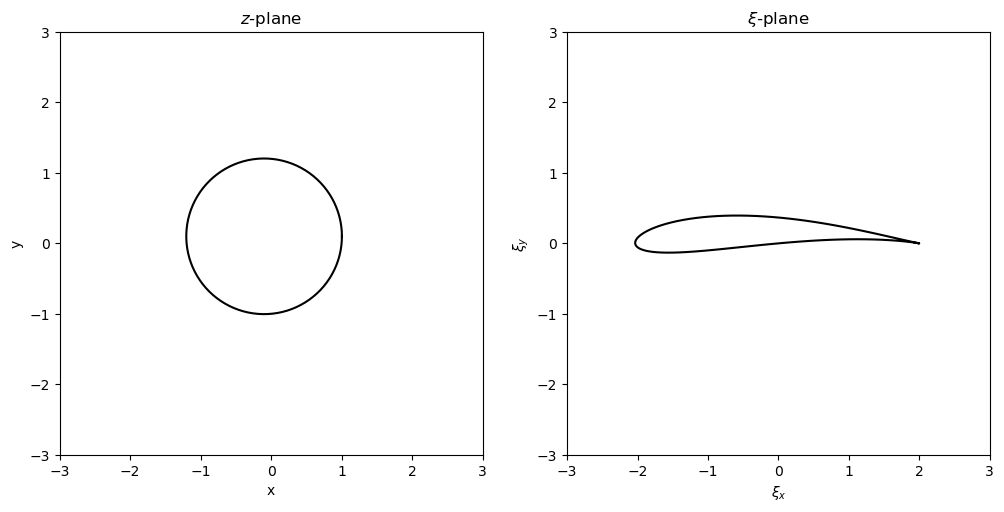

In [9]:
# 3.

dx = 0.1
dy = 0.1
xc = -dx
yc = dy
R = np.sqrt((c - xc)**2 + yc**2)
theta = np.linspace(0, 2 * np.pi, 100)
z =  (xc + yc * 1j) + R * np.exp(1j * theta)
xi = joukowski_transformation(z, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z.real, z.imag, color='k')
ax[0].set_xlim(-3, 3)
ax[0].set_ylim(-3, 3)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi.real, xi.imag, color='k')
ax[1].set_xlim(-3, 3)
ax[1].set_ylim(-3, 3)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

3. Put a circle at $(x_c, y_c)=(-\Delta x, \Delta y)$, where $\Delta x$ and $\Delta y$ are small positive numbers, e.g. $\Delta x=0.1$ and $\Delta y=0.1$. The radius $R$ of the circle is $R = \sqrt{(c - x_c)^2 + y_c^2}$. What does the shape on $\xi$-plane look like?
    4. cambered airfoil

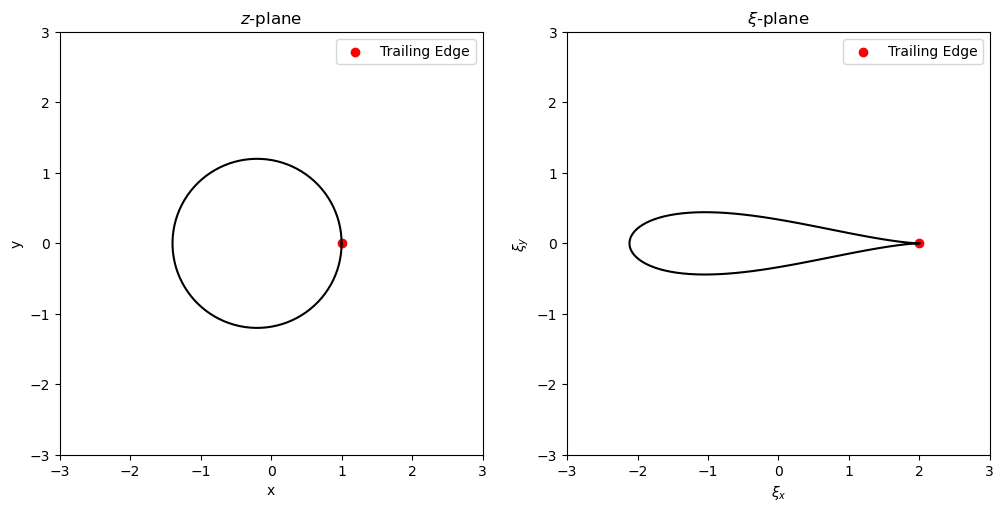

In [10]:
# 4.

R = 1.2
theta = np.linspace(0, 2 * np.pi, 100)
xc = c - R
yc = 0
z =  (xc + yc * 1j) + R * np.exp(1j * theta)
xi = joukowski_transformation(z, c)
te = np.argmax(xi.real)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z.real, z.imag, color='k')
ax[0].scatter(z[te].real, z[te].imag, color='r', label='Trailing Edge')
ax[0].set_xlim(-3, 3)
ax[0].set_ylim(-3, 3)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].legend()
ax[0].set_title('$z$-plane')

ax[1].plot(xi.real, xi.imag, color='k')
ax[1].scatter(xi[te].real, xi[te].imag, color='r', label='Trailing Edge')
ax[1].set_xlim(-3, 3)
ax[1].set_ylim(-3, 3)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].legend()
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [11]:
display(Markdown(rf"""
4. Consider the case when you obtain a symmetric airfoil. In polar coordinates, $(\theta, r=R)$, which point on the circle corresponds to the trailing edge of the airfoil?
    * $\theta={theta[te]:.2f}$ radians
"""))


4. Consider the case when you obtain a symmetric airfoil. In polar coordinates, $(\theta, r=R)$, which point on the circle corresponds to the trailing edge of the airfoil?
    * $\theta=0.00$ radians


## 3. Grid points on the $z$-plane using polar coordinates

### Exercise

1. Build a grid in polar coordinates in the $z$-plane. Use $N_r = 100$ points in the radial direction, within the range $R \le r \le 5$, and $N_\theta = 145$ points in the axial direction, within the range $0 \le \theta \le 2\pi$.
2. Use the Joukowski transformation to map the grid into the $\xi$-plane.
3. Plot the grid points in both planes using the function `pyplot.scatter()`.

In [12]:
# 1.
R = 1.15
radius_start, radius_end = R, 5
theta_start, theta_end = 0, 2 * np.pi
nradius, ntheta = 100, 145
xc, yc = -0.15, 0

complex_grid = PolarGrid(radius_start, radius_end, theta_start, theta_end, nradius, ntheta, xc, yc)

c = 1

z = complex_grid.X + complex_grid.Y * 1j

In [13]:
# 2.

xi = joukowski_transformation(z, c)

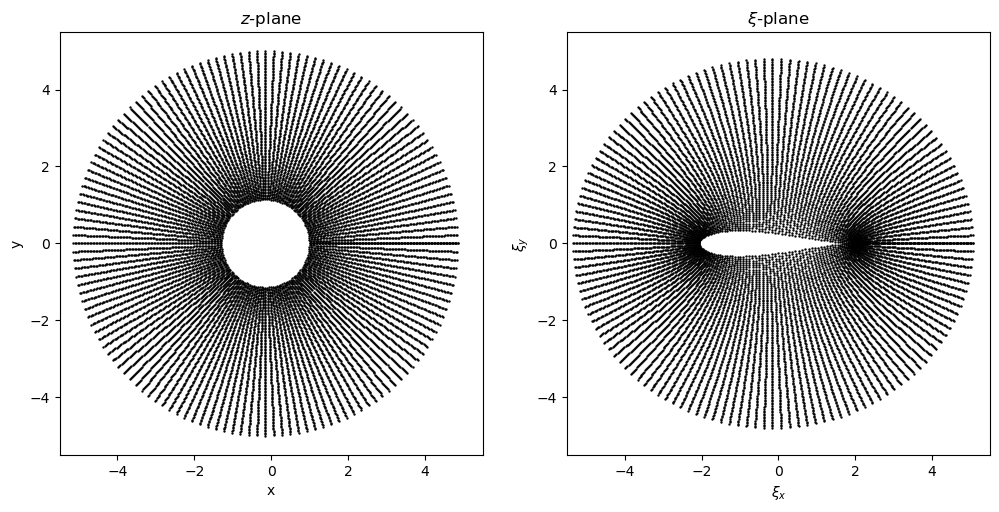

In [14]:
# 3.
x_start, x_end = -5.5, 5.5
y_start, y_end = -5.5, 5.5

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].scatter(z.real, z.imag, color='k', s=0.5, marker='o')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].scatter(xi.real, xi.imag, color='k', s=0.5, marker='o')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

## 4. Flow over a symmetric Joukowski airfoil with zero angle of attack

In [15]:
u_inf = 1.0
freestream = UniformFlow(U_inf=u_inf)

In [16]:
kappa = R**2 * 2 * np.pi * freestream.U_inf
doublet = Doublet(xd=xc, yd=yc, strength=kappa)

In [17]:
doublet_freestream = DoubletFreestream(doublet, freestream)
psi = doublet_freestream.stream_function(complex_grid)

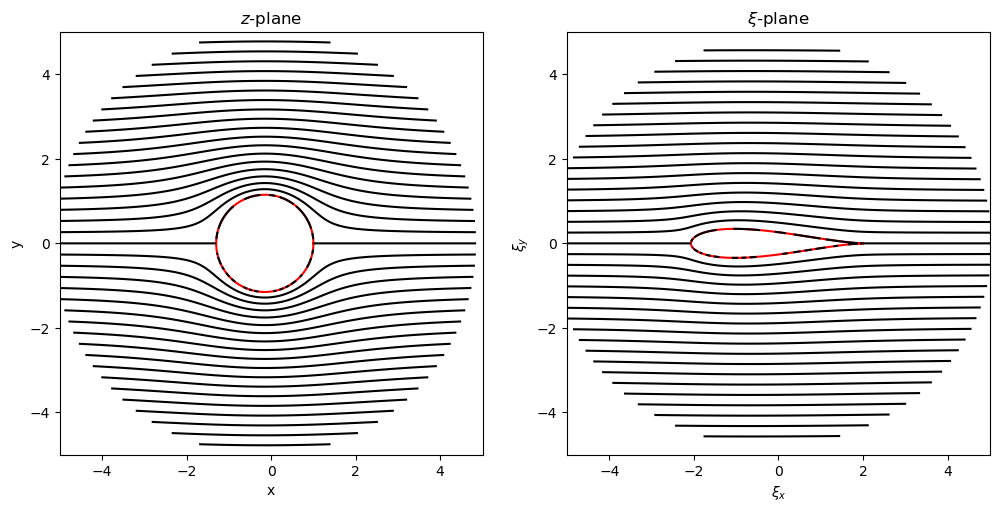

In [18]:
# 3.
x_start, x_end = -5, 5
y_start, y_end = -5, 5

theta = np.linspace(0, 2 * np.pi, 100)

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].contour(z.real, z.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contour(xi.real, xi.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [19]:
u, v = doublet_freestream.velocity_field(complex_grid)

w_z = u - v * 1j
w_xi = w_z / (1 - (c/z)**2)

u_xi = w_xi.real
v_xi = -w_xi.imag

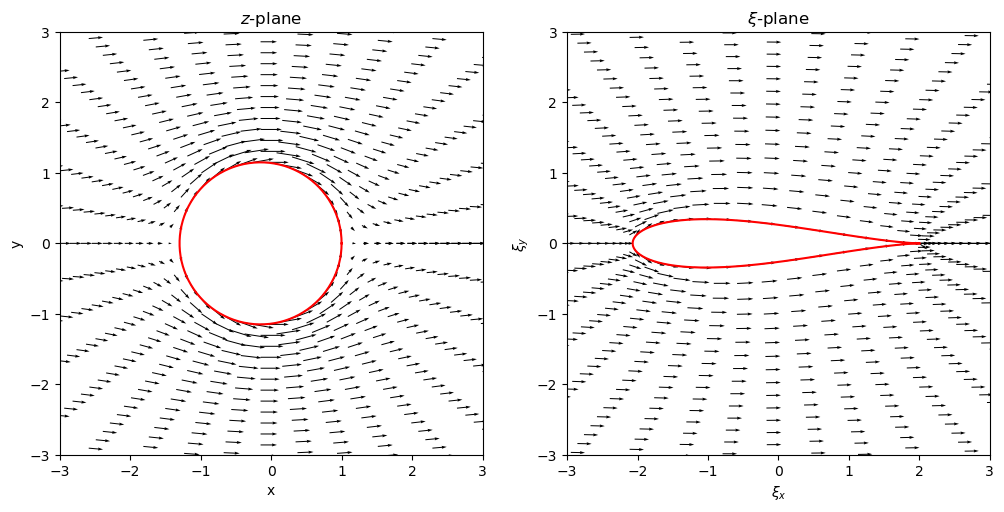

In [20]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].quiver(
    z.real[::steps, ::steps], 
    z.imag[::steps, ::steps], 
    u[::steps, ::steps], 
    v[::steps, ::steps], 
    scale=30
)
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].quiver(
    xi.real[::steps, ::steps], 
    xi.imag[::steps, ::steps], 
    u_xi[::steps, ::steps], 
    v_xi[::steps, ::steps], 
    scale=30
)
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [21]:
cp_z = doublet_freestream.pressure_coefficient(complex_grid)

cp_xi = 1 - (np.abs(w_xi) / freestream.U_inf)**2

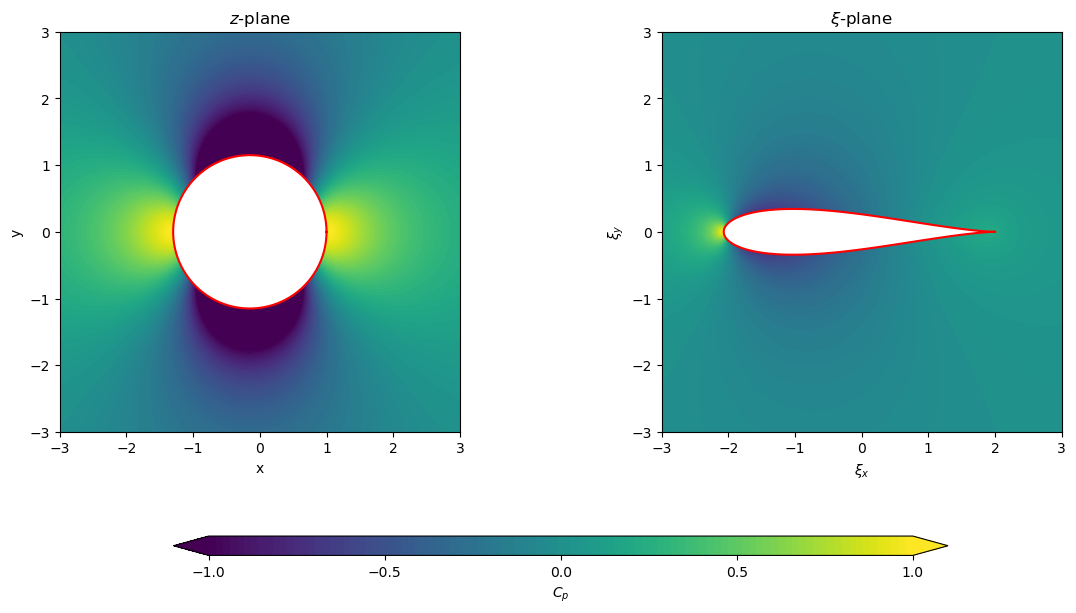

In [22]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4
levels = np.linspace(-1, 1, 100)

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

fig, ax = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
ax[0].plot(z_circle.real, z_circle.imag, color='r')
contf = ax[0].contourf(z.real, z.imag, cp_z,
              levels=levels, cmap='viridis', extend='both')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contourf(xi.real, xi.imag, cp_xi,
              levels=levels, cmap='viridis', extend='both')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')

cbar = fig.colorbar(
    contf, ax=ax,
    location='bottom',
    shrink=0.65,
    aspect=40,
    pad=0.12
)
cbar.set_label('$C_p$')
cbar.set_ticks(np.linspace(-1, 1, 5))

plt.show()

In [23]:
display(Markdown(rf"""
### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in both planes).
* Answer the following questions:
    1. What is the strength of the doublet? $\kappa={kappa:.2f}$.
    2. What is the velocity at the $62^\text{{nd}}$ point on the airfoil surface? 
    (We assume that the trailing edge is the $1^\text{{st}}$ point and that we index the points counterclockwise.)
    $|W_\xi|$ = {np.abs(w_xi[61, 0]):.2f}.
    3. What is the minimum value of the pressure coefficient on the airfoil surface?
    $Cp$ = {np.nanmin(cp_xi[:, 0]):.2f}.   
"""))


### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in both planes).
* Answer the following questions:
    1. What is the strength of the doublet? $\kappa=8.31$.
    2. What is the velocity at the $62^\text{nd}$ point on the airfoil surface? 
    (We assume that the trailing edge is the $1^\text{st}$ point and that we index the points counterclockwise.)
    $|W_\xi|$ = 1.22.
    3. What is the minimum value of the pressure coefficient on the airfoil surface?
    $Cp$ = -0.69.   


## 5. Flow over a symmetric Joukowski airfoil with non-zero angle of attack, without circulation

In [24]:
aoa = np.deg2rad(20)

z_prime = (z - (xc + yc * 1j)) * np.exp(-1j*aoa)

In [25]:
complex_grid_prime = PolarGrid(radius_start, radius_end, theta_start, theta_end,
                               nradius, ntheta, 0.0, 0.0)

complex_grid_prime.X = z_prime.real
complex_grid_prime.Y = z_prime.imag

In [26]:
xc_prime, yc_prime = 0.0, 0.0

doublet = Doublet(xd=xc_prime, yd=yc_prime, strength=kappa)

In [27]:
doublet_freestream = DoubletFreestream(doublet, freestream)
psi = doublet_freestream.stream_function(complex_grid_prime)

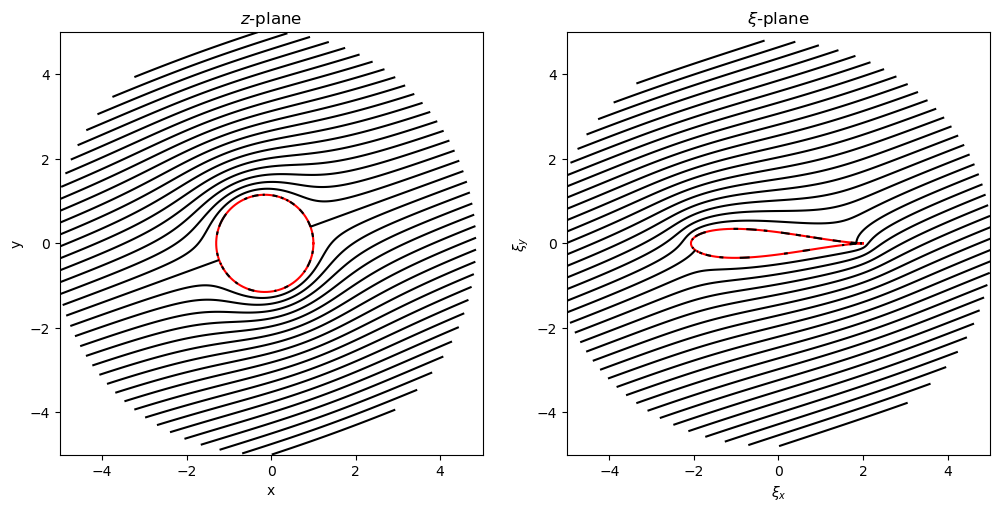

In [28]:
# 3.
x_start, x_end = -5, 5
y_start, y_end = -5, 5

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].contour(z.real, z.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contour(xi.real, xi.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [29]:
u_prime, v_prime = doublet_freestream.velocity_field(complex_grid_prime)

w_z_prime = u_prime - v_prime * 1j
w_z = w_z_prime * np.exp(-1j * aoa)
u_z = w_z.real
v_z = -w_z.imag

w_xi = w_z / (1 - (c/z)**2)
u_xi = w_xi.real
v_xi = -w_xi.imag

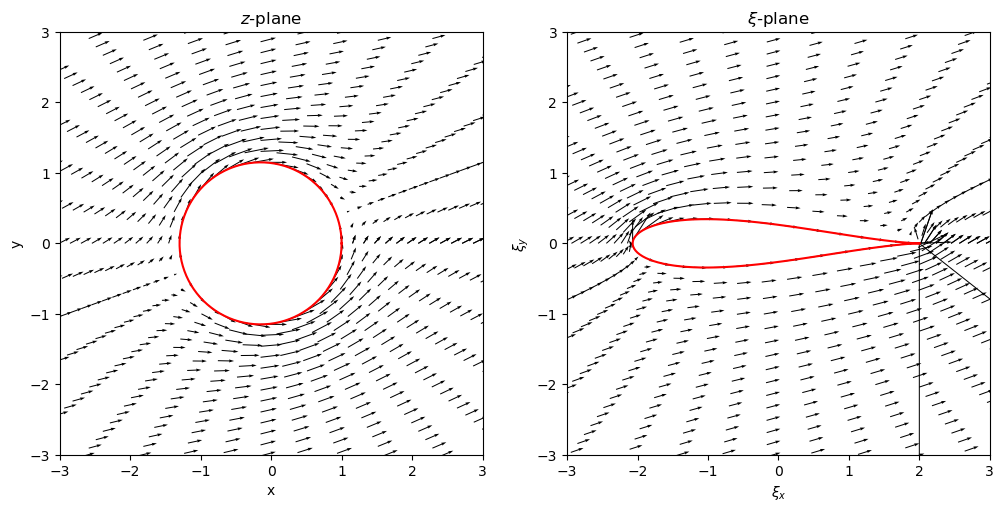

In [30]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].quiver(
    z.real[::steps, ::steps], 
    z.imag[::steps, ::steps], 
    u_z[::steps, ::steps], 
    v_z[::steps, ::steps], 
    scale=30
)
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].quiver(
    xi.real[::steps, ::steps], 
    xi.imag[::steps, ::steps], 
    u_xi[::steps, ::steps], 
    v_xi[::steps, ::steps], 
    scale=30
)
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [31]:
cp_z = doublet_freestream.pressure_coefficient(complex_grid_prime)

cp_xi = 1 - (np.abs(w_xi) / freestream.U_inf)**2

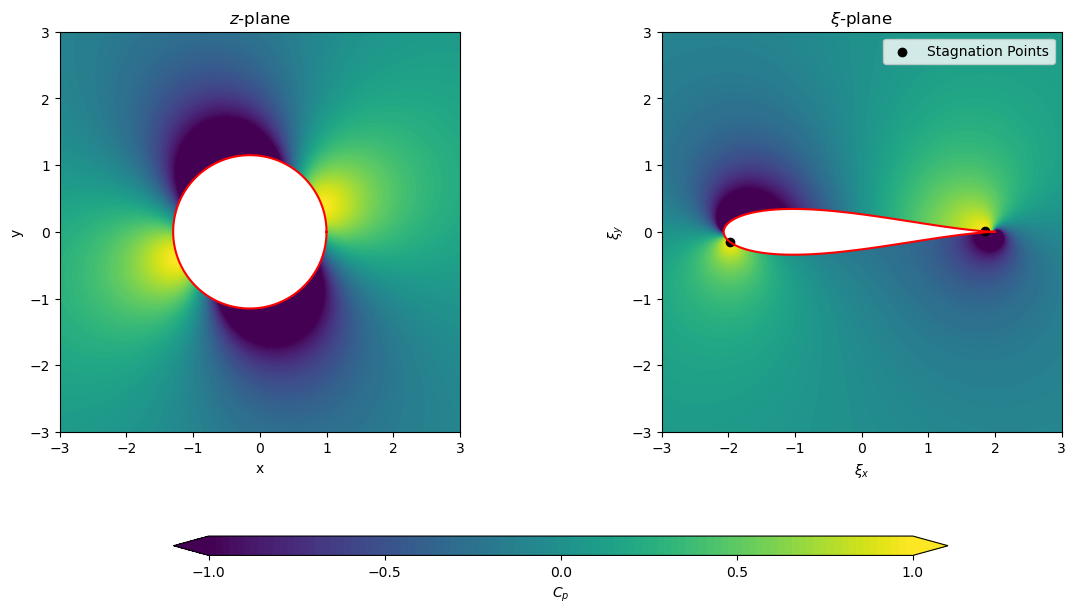

In [32]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4
levels = np.linspace(-1, 1, 100)

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

stag_mask = np.abs(w_xi) < 1e-6

x_stag_xi = xi.real[stag_mask]
y_stag_xi = xi.imag[stag_mask]

fig, ax = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
ax[0].plot(z_circle.real, z_circle.imag, color='r')
contf = ax[0].contourf(z.real, z.imag, cp_z,
              levels=levels, cmap='viridis', extend='both')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contourf(xi.real, xi.imag, cp_xi,
              levels=levels, cmap='viridis', extend='both')
ax[1].scatter(x_stag_xi, y_stag_xi, c='k', label='Stagnation Points')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].legend()
ax[1].set_title(r'$\xi$-plane')

cbar = fig.colorbar(
    contf, ax=ax,
    location='bottom',
    shrink=0.65,
    aspect=40,
    pad=0.12
)
cbar.set_label('$C_p$')
cbar.set_ticks(np.linspace(-1, 1, 5))

plt.show()

In [33]:
rho = 1
cp = cp_xi[:, 0]
x = xi[1:-1, 0].real
y = xi[1:-1, 0].imag

dx = np.diff(x)
dy = np.diff(y)
cp_mid = 0.5 * (cp[:-1] + cp[1:])

lift = 0.5 * rho * u_inf**2 * np.sum(
    cp_mid[1:-1] * (dx*np.cos(aoa) + dy*np.sin(aoa))
)

drag = 0.5 * rho * u_inf**2 * np.sum(
    cp_mid[1:-1] * (dx*np.sin(aoa) - dy*np.cos(aoa))
)

In [34]:
display(Markdown(rf"""
### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in the $z$ and $\xi$ planes). Set the angle of attack to $\text{{AoA}} = 20^\circ$.
* Answer the following questions:
    1. Do you think the flow over the airfoil looks reasonable? Explain why.
    No I don't think the flow over the airfoil looks reasonable, because the rear stagnation point sits at θ = AoA, not at the trailing edge. 
    The flow wraps around the sharp trailing edge with infinite speed there. 
    That breaks the Kutta condition, and the airfoil produces no lift.
    2. What are the index of the stagnation points on the airfoil? (We assume that the trailing edge is the $1^\text{{st}}$ point and that we index the points counterclockwise.)
    Indices = {(np.flatnonzero(stag_mask[:-1, 0]) + 1).tolist()}.
    3. How much is the lift? The lift, $L=-\oint p \times \sin{{\theta}} dA$, is perpendicular to the free-stream direction.
    Lift = {lift:.2f}. The exact answer is L = 0 (no circulation). The {lift:.2f} is numerical error from the coarse grid near the trailing edge, where the speed is infinite.
    4. How much is the drag? The drag, $D=-\oint p \times \cos{{\theta}} dA$, is in the direction of the free-stream.
    Drag = {drag:.2f}. The exact answer is D = 0 (d'Alembert's paradox). The {drag:.2f} is numerical error from the coarse grid near the trailing edge, where the speed is infinite.
    5. What is the velocity at the $50^\text{{th}}$ point on the airfoil?
    $|W_\xi|$ = {np.abs(w_xi[49, 0]):.2f}.
    6. What is the pressure coefficient at the $75^\text{{th}}$ point on the airfoil?  
    $Cp$ = {cp_xi[74, 0]:.2f}.  
"""))


### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in the $z$ and $\xi$ planes). Set the angle of attack to $\text{AoA} = 20^\circ$.
* Answer the following questions:
    1. Do you think the flow over the airfoil looks reasonable? Explain why.
    No I don't think the flow over the airfoil looks reasonable, because the rear stagnation point sits at θ = AoA, not at the trailing edge. 
    The flow wraps around the sharp trailing edge with infinite speed there. 
    That breaks the Kutta condition, and the airfoil produces no lift.
    2. What are the index of the stagnation points on the airfoil? (We assume that the trailing edge is the $1^\text{st}$ point and that we index the points counterclockwise.)
    Indices = [9, 81].
    3. How much is the lift? The lift, $L=-\oint p \times \sin{\theta} dA$, is perpendicular to the free-stream direction.
    Lift = 0.17. The exact answer is L = 0 (no circulation). The 0.17 is numerical error from the coarse grid near the trailing edge, where the speed is infinite.
    4. How much is the drag? The drag, $D=-\oint p \times \cos{\theta} dA$, is in the direction of the free-stream.
    Drag = -0.33. The exact answer is D = 0 (d'Alembert's paradox). The -0.33 is numerical error from the coarse grid near the trailing edge, where the speed is infinite.
    5. What is the velocity at the $50^\text{th}$ point on the airfoil?
    $|W_\xi|$ = 1.49.
    6. What is the pressure coefficient at the $75^\text{th}$ point on the airfoil?  
    $Cp$ = -0.49.  


## 6. Flow over a symmetric Joukowski airfoil with non-zero angle of attack, with circulation

In [35]:
gamma = 4 * np.pi * freestream.U_inf * R  * np.sin(aoa)

In [36]:
vortex = Vortex(x=xc_prime, y=yc_prime, gamma=gamma)

In [37]:
doublet_vortex_freestream = DoubletVortexFreestream(doublet, vortex, freestream)

In [38]:
psi = doublet_vortex_freestream.stream_function(complex_grid_prime)

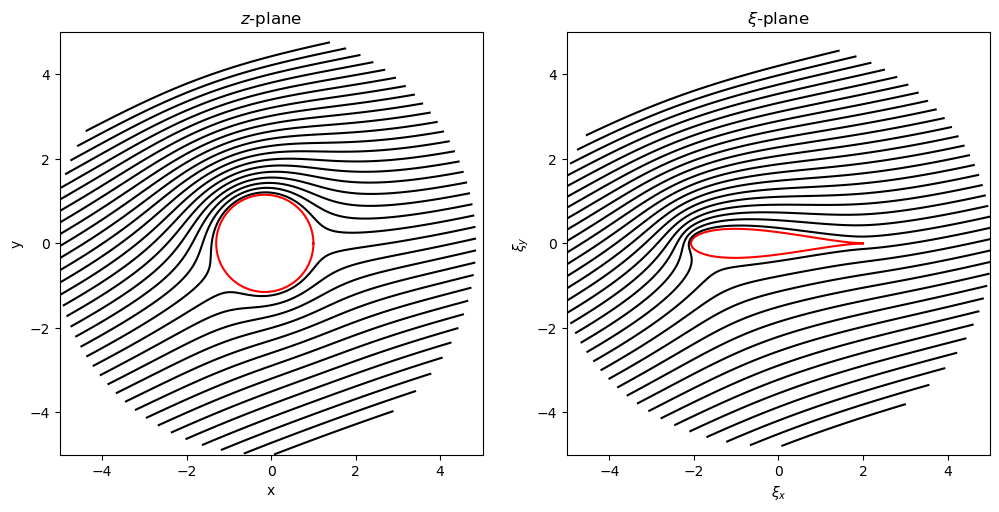

In [39]:
# 3.
x_start, x_end = -5, 5
y_start, y_end = -5, 5

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].contour(z.real, z.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contour(xi.real, xi.imag, psi,
              levels=np.linspace(y_start, y_end, 41), colors='k', linestyles='solid')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [40]:
u_prime, v_prime = doublet_vortex_freestream.velocity_field(complex_grid_prime)

w_z_prime = u_prime - v_prime * 1j
w_z = w_z_prime * np.exp(-1j * aoa)
u_z = w_z.real
v_z = -w_z.imag

w_xi = w_z / (1 - (c/z)**2)
u_xi = w_xi.real
v_xi = -w_xi.imag

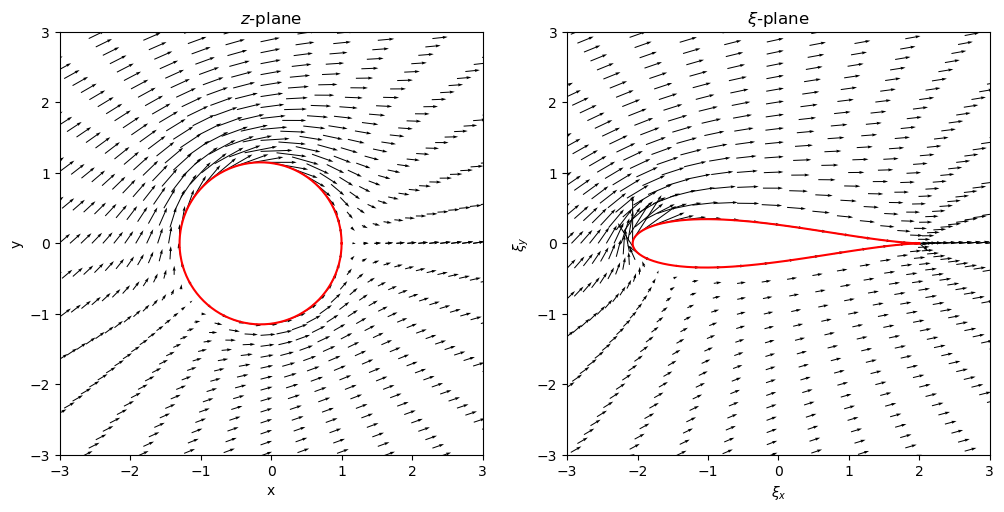

In [41]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].plot(z_circle.real, z_circle.imag, color='r')
ax[0].quiver(
    z.real[::steps, ::steps], 
    z.imag[::steps, ::steps], 
    u_z[::steps, ::steps], 
    v_z[::steps, ::steps], 
    scale=30
)
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].quiver(
    xi.real[::steps, ::steps], 
    xi.imag[::steps, ::steps], 
    u_xi[::steps, ::steps], 
    v_xi[::steps, ::steps], 
    scale=30
)
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].set_title(r'$\xi$-plane')
plt.show()

In [42]:
cp_z = doublet_vortex_freestream.pressure_coefficient(complex_grid_prime)

cp_xi = 1 - (np.abs(w_xi) / freestream.U_inf)**2

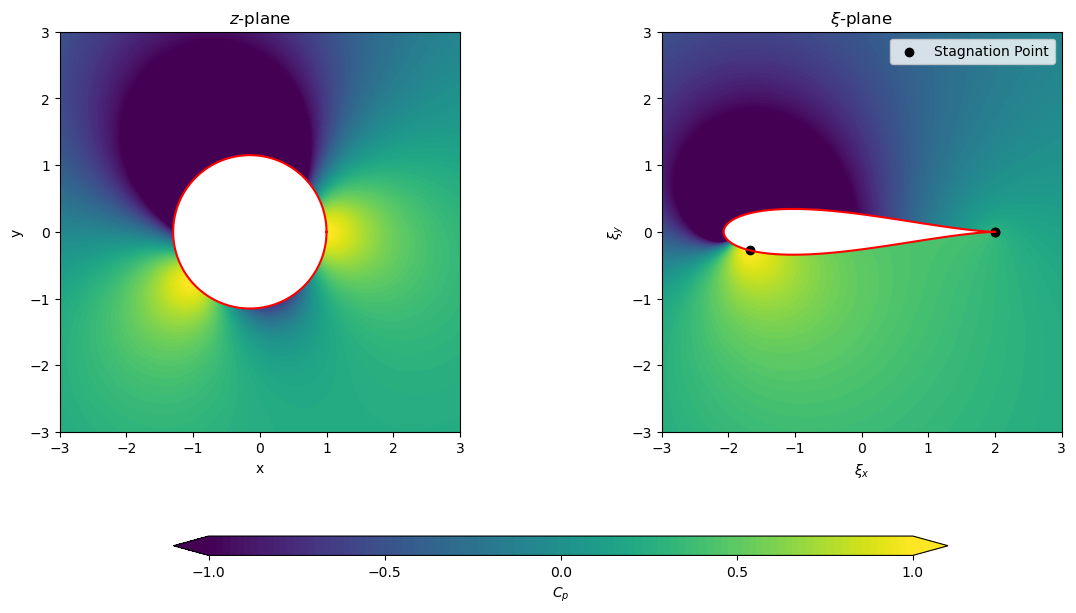

In [43]:
# 3.
x_start, x_end = -3, 3
y_start, y_end = -3, 3

steps = 4
levels = np.linspace(-1, 1, 100)

z_circle = (xc + yc * 1j) + R * np.exp(1j * theta)
xi_circle = joukowski_transformation(z_circle, c)

stag_mask = np.abs(w_z) < 1e-6

x_stag_xi = xi.real[stag_mask]
y_stag_xi = xi.imag[stag_mask]

fig, ax = plt.subplots(1, 2, figsize=(12, 6), layout='constrained')
ax[0].plot(z_circle.real, z_circle.imag, color='r')
contf = ax[0].contourf(z.real, z.imag, cp_z,
              levels=levels, cmap='viridis', extend='both')
ax[0].set_xlim(x_start, x_end)
ax[0].set_ylim(y_start, y_end)
ax[0].set_aspect("equal")
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('$z$-plane')

ax[1].plot(xi_circle.real, xi_circle.imag, color='r')
ax[1].contourf(xi.real, xi.imag, cp_xi,
              levels=levels, cmap='viridis', extend='both')
ax[1].scatter(x_stag_xi, y_stag_xi, c='k', label='Stagnation Point')
ax[1].set_xlim(x_start, x_end)
ax[1].set_ylim(y_start, y_end)
ax[1].set_aspect("equal")
ax[1].set_xlabel(r'$\xi_x$')
ax[1].set_ylabel(r'$\xi_y$')
ax[1].legend()
ax[1].set_title(r'$\xi$-plane')

cbar = fig.colorbar(
    contf, ax=ax,
    location='bottom',
    shrink=0.65,
    aspect=40,
    pad=0.12
)
cbar.set_label('$C_p$')
cbar.set_ticks(np.linspace(-1, 1, 5))

plt.show()

In [44]:
rho = 1
cp = cp_xi[:, 0]
x = xi[:, 0].real
y = xi[:, 0].imag

dx = np.diff(x)
dy = np.diff(y)
cp_mid = 0.5 * (cp[:-1] + cp[1:])

lift = 0.5 * rho * u_inf**2 * np.sum(
    cp_mid * (dx*np.cos(aoa) + dy*np.sin(aoa))
)

drag = 0.5 * rho * u_inf**2 * np.sum(
    cp_mid * (dx*np.sin(aoa) - dy*np.cos(aoa))
)

In [45]:
display(Markdown(rf"""
### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in the $z$ and $\xi$ planes). Set the angle of attack to $\text{{AoA}} = 20^\circ$.
* Answer the following questions:
    1. What is the strength of the vortex? $\Gamma$ = {gamma:.2f}.
    2. How much is the lift and does it agree with the Kutta-Joukowski theorem? The lift, $L=-\oint p \times \sin{{\theta}} dA$, is perpendicular to the free-stream direction.
    The lift is {lift:.2f} and yes it agrees with the Kutta-Joukowski theorem.
    3. How much is the drag? The drag, $D=-\oint p \times \cos{{\theta}} dA$, is in the direction of the free-stream.
    Drag = {drag:.2f}.
    4. What are the index of the stagnation points on the airfoil? (We assume that the trailing edge is the $1^\text{{st}}$ point and that we index the points counterclockwise.)
    Indices on the cylinder ($z$-plane) = {(np.flatnonzero(stag_mask[:-1, 0]) + 1).tolist()}.
    Point 1 is the rear stagnation point on the cylinder. On the cusped airfoil the speed there is finite
    ($|W_\xi| \approx$ {0.5 * (np.abs(w_xi[1, 0]) + np.abs(w_xi[-2, 0])):.2f}, see Q7),
    so in the $\xi$-plane only point(s) {(np.flatnonzero(np.abs(w_xi[:-1, 0]) < 1e-6) + 1).tolist()} are true stagnation points.
    5. What is the velocity at the $92^\text{{nd}}$ point on the airfoil?
    $|W_\xi|$ = {np.abs(w_xi[91, 0]):.2f}.
    6. What is the pressure coefficient at the $111^\text{{th}}$ point on the airfoil?
    $Cp$ = {cp_xi[110, 0]:.2f}.  
    7. Explain what is going on with the pressure coefficient at the trailing edge of the airfoil.
        * The cylinder's stagnation point now sits exactly where the transformation's derivative dξ/dz is zero, so the airfoil-plane speed is 0/0 there.
        * The limit is finite ($|W_\xi|$ = {0.5 * (np.abs(w_xi[1,0]) + np.abs(w_xi[-2,0])):.2f} here), so Cp at the trailing edge is finite ($Cp$ = {0.5 * (cp_xi[1,0] + cp_xi[-2,0]):.2f}), not 1 and not singular.
        * The upper and lower surfaces reach the same pressure, and the flow leaves the trailing edge smoothly, as the Kutta condition requires.
"""))


### Exercise

* Write the Python code to obtain the figures shown above (streamlines, velocity field, and pressure coefficient in the $z$ and $\xi$ planes). Set the angle of attack to $\text{AoA} = 20^\circ$.
* Answer the following questions:
    1. What is the strength of the vortex? $\Gamma$ = 4.94.
    2. How much is the lift and does it agree with the Kutta-Joukowski theorem? The lift, $L=-\oint p \times \sin{\theta} dA$, is perpendicular to the free-stream direction.
    The lift is 4.94 and yes it agrees with the Kutta-Joukowski theorem.
    3. How much is the drag? The drag, $D=-\oint p \times \cos{\theta} dA$, is in the direction of the free-stream.
    Drag = 0.00.
    4. What are the index of the stagnation points on the airfoil? (We assume that the trailing edge is the $1^\text{st}$ point and that we index the points counterclockwise.)
    Indices on the cylinder ($z$-plane) = [1, 89].
    Point 1 is the rear stagnation point on the cylinder. On the cusped airfoil the speed there is finite
    ($|W_\xi| \approx$ 0.82, see Q7),
    so in the $\xi$-plane only point(s) [89] are true stagnation points.
    5. What is the velocity at the $92^\text{nd}$ point on the airfoil?
    $|W_\xi|$ = 0.21.
    6. What is the pressure coefficient at the $111^\text{th}$ point on the airfoil?
    $Cp$ = 0.50.  
    7. Explain what is going on with the pressure coefficient at the trailing edge of the airfoil.
        * The cylinder's stagnation point now sits exactly where the transformation's derivative dξ/dz is zero, so the airfoil-plane speed is 0/0 there.
        * The limit is finite ($|W_\xi|$ = 0.82 here), so Cp at the trailing edge is finite ($Cp$ = 0.33), not 1 and not singular.
        * The upper and lower surfaces reach the same pressure, and the flow leaves the trailing edge smoothly, as the Kutta condition requires.
